# Pertemuan 11 — Praktikum 5: Klasifikasi Citra Siang dan Malam

Praktikum ini mengklasifikasikan citra **day** (siang) dan **night** (malam) dengan pendekatan sederhana berbasis *threshold* dan dengan model SVM. Fitur yang dipakai adalah rata-rata kecerahan gambar pada ruang warna HSV.

Sumber: [Praktikum 5](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js11-klasifikasi-2/praktikum-5).

## 1. Langkah 0 — Import Library dan Lokasi Gambar

In [1]:
%matplotlib inline
# Import Required Libraries
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import random
import numpy as np
import pandas as pd

In [2]:
# Image directories
train_dir = "images/training/"
test_dir = "images/test/"


## 2. Langkah 1 — Load Data dan Visualisasikan

Fungsi `load_dataset` membaca seluruh gambar di dalam direktori dan menyimpannya bersama label (nama folder) dalam sebuah list.

In [3]:
def load_dataset(img_dir):
    p = Path(img_dir)
    dirs = p.glob('*')

    img_list = []

    for dir in dirs:
        label = str(dir).split('/')[-1]
        for file in dir.glob('*.jpg'):
            img = mpimg.imread(file)

            if img is not None:
                img_list.append((img, label))

    return img_list

Load data training.

In [4]:
# Load training data
train_img = load_dataset(train_dir)

Cek data pertama. List berisi tuple dengan dua elemen, yaitu array gambar dan label gambar.

In [5]:
# Check the first data
train_img[0]

(array([[[253, 255, 252],
         [253, 255, 252],
         [253, 255, 252],
         ...,
         [ 75,  93,  93],
         [ 73,  91,  91],
         [ 74,  92,  92]],
 
        [[253, 255, 252],
         [253, 255, 252],
         [253, 255, 252],
         ...,
         [ 77,  95,  95],
         [ 76,  94,  94],
         [ 78,  96,  96]],
 
        [[253, 255, 252],
         [253, 255, 252],
         [253, 255, 252],
         ...,
         [ 75,  93,  93],
         [ 74,  92,  92],
         [ 76,  94,  94]],
 
        ...,
 
        [[108, 112, 113],
         [ 98, 102, 103],
         [ 90,  94,  95],
         ...,
         [ 43,  45,  32],
         [ 45,  47,  34],
         [ 48,  50,  37]],
 
        [[107, 111, 112],
         [ 97, 101, 102],
         [ 90,  94,  95],
         ...,
         [ 42,  44,  31],
         [ 45,  47,  34],
         [ 48,  50,  37]],
 
        [[100, 104, 105],
         [ 91,  95,  96],
         [ 86,  90,  91],
         ...,
         [ 42,  44,  31],
  

Cek ukuran gambar secara acak.

In [6]:
# Random size checking
pick_random = np.random.randint(0, len(train_img))

# Check img size
print(f'Image {pick_random}')
print(train_img[pick_random][0].shape)

Image 166
(469, 640, 3)


Buat fungsi untuk memvisualisasikan gambar secara acak.

In [7]:
# Function to Visualize
def random_img_viz(img_list):
    rand_num = np.random.randint(0, len(img_list))

    img = img_list[rand_num][0]
    label = img_list[rand_num][1]

    plt.imshow(img)
    print(f'Shape\t: {img.shape}')
    print(f'Label\t: {label}')

Tampilkan gambar secara acak.

Shape	: (469, 640, 3)
Label	: night


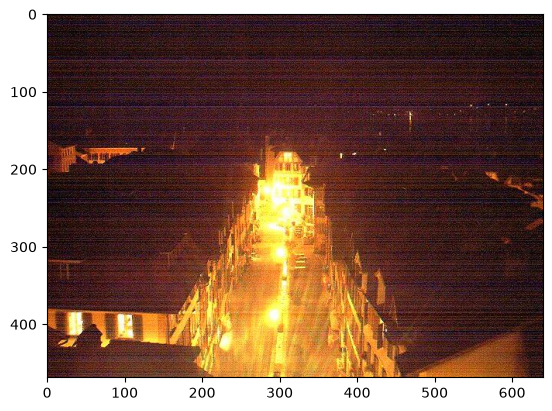

In [8]:
random_img_viz(train_img)

## 3. Langkah 2 — Pra Pengolahan Data

Pra pengolahan terdiri dari dua proses utama: standardisasi ukuran gambar dan encoding label (day = 1, night = 0).

In [9]:
def standarized_input(image):
    # resize to w: 1100, h: 600
    std_img = cv2.resize(image, (1100, 600))

    return std_img


def label_encoder(label):
    # Encode the label: day as 1; night as 0
    num_val = 0

    if label == 'day':
        num_val = 1

    return num_val


def preprocess(img_list):
    std_img_list = []

    for item in img_list:
        image = item[0]
        label = item[1]

        # Standarized the image
        std_img = standarized_input(image)

        # Create the label
        img_label = label_encoder(label)

        std_img_list.append((std_img, img_label))

    return std_img_list

Lakukan pra pengolahan pada data training.

In [10]:
train_std_img_list = preprocess(train_img)

Cek ukuran gambar hasil pra pengolahan secara acak.

In [11]:
# Random size checking
pick_random = np.random.randint(0, len(train_std_img_list))

# Check img size
print(f'Image {pick_random}')
print(train_std_img_list[pick_random][0].shape)

Image 124
(600, 1100, 3)


## 4. Langkah 3 — Ekstraksi Fitur (Average Brightness)

Fitur yang membedakan siang dan malam adalah rata-rata kecerahan. Gambar diubah dari RGB ke ruang warna HSV, lalu kecerahan diambil dari kanal **V (Value)**.

In [12]:
# Get feature based on average brightness using HSV colorspace
def avg_brightness(image):
    # Convert image to HSV
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    # Calculate the avg of brightness (V channel)
    sum_brightness = np.sum(img_hsv[:, :, 2])
    area = image.shape[0] * image.shape[1]
    avg = sum_brightness / area

    return avg

Cek rata-rata kecerahan pada gambar acak hasil pra pengolahan.

Image 132
Avg Brighness: 8.3054


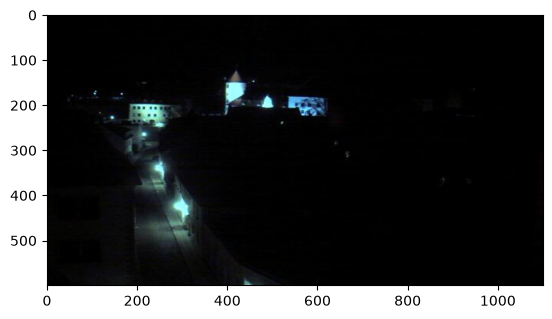

In [13]:
# Check on random image
rand_img = np.random.randint(0, len(train_std_img_list))

feature_img = train_std_img_list[rand_img][0]

avg_img = avg_brightness(feature_img)

print(f'Image {rand_img}')
print(f'Avg Brighness: {avg_img:.4f}')
plt.imshow(feature_img)

## 5. Langkah 4 — Klasifikasi dengan Metode Threshold

Klasifikasi sederhana memakai nilai ambang batas (threshold) dari rata-rata kecerahan.

In [14]:
def predict_label(img, threshold):
    # Compute average brightness
    avg = avg_brightness(img)
    pred = 0

    # Predict the label based on user defined threshold
    if avg > threshold:
        pred = 1

    return pred

Cek prediksi secara acak pada data training.

Image 217
Actual label: 0
Predicted label: 0


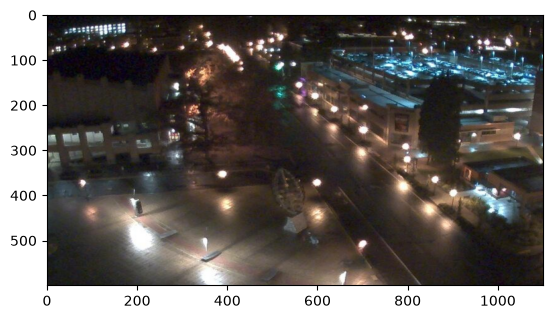

In [15]:
# Test the classifier on train data
rand_img = np.random.randint(0, len(train_std_img_list))

pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

# Evaluate
print(f'Image {rand_img}')
print(f'Actual label: {train_std_img_list[rand_img][1]}')
print(f'Predicted label: {pred}')
plt.imshow(train_std_img_list[rand_img][0])

## 6. Langkah 5 — Evaluasi Manual

Evaluasi membandingkan label prediksi dengan label sebenarnya untuk menghitung akurasi.

In [16]:
def evaluate(img_list, threshold):
    miss_labels = []

    for file in img_list:
        # Get the ground truth / correct label
        img = file[0]
        label = file[1]

        # Get prediction
        pred_label = predict_label(img, threshold)

        # Compare ground truth and pred
        if pred_label != label:
            miss_labels.append((img, pred_label, label))

    total_img = len(img_list)
    corr_pred = total_img - len(miss_labels)
    accuracy = corr_pred / total_img

    print(f'Accuracy: {accuracy:.4f}')

Evaluasi pada data training dengan threshold = 120.

In [17]:
# Evaluate on train data
evaluate(train_std_img_list, threshold=120)

Accuracy: 0.8417


Evaluasi pada data testing dengan threshold = 120.

In [18]:
# Evaluate on test data
test_img = load_dataset(test_dir)
test_std_img_list = preprocess(test_img)
evaluate(test_std_img_list, threshold=120)

Accuracy: 0.8688


## Klasifikasi dengan SVM

Setelah pendekatan threshold, model SVM digunakan dengan fitur rata-rata kecerahan yang ditabulasikan menjadi sebuah DataFrame.

## 7. Langkah 4 Alternatif — Membuat Feature Vectors

In [19]:
# Create function to extract feature for every images and stored in tabular data
def extract_avg_bright_feature(img_list):
    avg_list = []
    labels = []

    for img in img_list:
        img_avg = avg_brightness(img[0])
        img_label = img[1]

        avg_list.append(img_avg)
        labels.append(img_label)

    # Stack data in columnar way
    data = np.column_stack((avg_list, labels))
    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])

    return df

Ekstraksi fitur pada data training.

In [20]:
train_avg_img = extract_avg_bright_feature(train_std_img_list)
print(f'Shape: {train_avg_img.shape}')
train_avg_img.head()

Shape: (240, 2)


,AVG_BRIGHT,LABELS
0,137.345858,1.0
1,129.128358,1.0
2,200.020276,1.0
3,165.241074,1.0
4,191.533608,1.0


Ekstraksi fitur pada data testing.

In [21]:
test_avg_img = extract_avg_bright_feature(test_std_img_list)
print(f'Shape: {test_avg_img.shape}')
test_avg_img.head()

Shape: (160, 2)


,AVG_BRIGHT,LABELS
0,157.918309,1.0
1,183.717738,1.0
2,132.656305,1.0
3,127.565042,1.0
4,150.264005,1.0


## 8. Langkah 5 — Buat Model SVM (kernel RBF default)

In [22]:
from sklearn.svm import SVC

# Split data and label
X_train = train_avg_img.iloc[:, 0].values.reshape(-1, 1)
y_train = train_avg_img.iloc[:, 1]
X_test = test_avg_img.iloc[:, 0].values.reshape(-1, 1)
y_test = test_avg_img.iloc[:, 1]

model = SVC()
model.fit(X_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


## 9. Langkah 6 — Evaluasi Model SVM

In [23]:
from sklearn.metrics import accuracy_score

# Make a prediction on train data
y_train_pred = model.predict(X_train)
acc_train = accuracy_score(y_train, y_train_pred)

# Make a prediction on test data
y_test_pred = model.predict(X_test)
acc_test = accuracy_score(y_test, y_test_pred)

# Print Eval Result
print(f'Accuracy on train: {acc_train}')
print(f'Accuracy on test: {acc_test}')

Accuracy on train: 0.8625
Accuracy on test: 0.9
